# Nested models and ablation of the time-varying weights

This notebook reproduces three analyses of the revision.

**Part I — Figure S3.** The ISI model is compared with a ladder of nested
models, each of which removes one ingredient of the full model. Every model is scored by
three-fold cross-validation across the three groups of females, and every model is given
its own grid search over the hyperparameters it actually has.

**Part II — Figure S11.** The signal importance of one channel at a time is
held constant in time, the model is refitted, and both the predictive accuracy and the
weights that remain are compared with the unconstrained model. Part II-2 repeats
this with the hyperparameters of each ablation model selected by its own grid search.

**Part III — Figure S4.** The
full analysis is repeated at seven values of the ridge penalty $\lambda$, and the
resulting solutions are compared with the reported one ($\lambda = 1$) after gauge
fixing. Unlike Parts I and II, this part starts from the precomputed per-$\lambda$
averaged solutions in `supresults_BestModelsForEachLamda/`, because repeating the
grid search of Part I at every penalty is too expensive for a notebook cell.

Parts I and II are computed from

    data/20151001_20171015_env_inGSI.csv
    data/20151001_20171015_raw_GSIdata_ci.csv

No intermediate result is read from disk in Parts I and II, so the numbers in their
figures are produced by the cells of this notebook alone; Part III is the one
exception, and Section 14 states which files it reads and how they were produced.

`ISI.py`, the module distributed with the paper, must be on the import path. It is used unchanged, apart from the subclass in Section 1, whose two
modifications are described there.

Part I contains a grid search of roughly 2300 EM fits and takes about half an hour on one
core.
Part II takes a few minutes and does not depend on Part I, so it can be run on its own after
Sections 1 to 5. Part III is self-contained and can be run without any other section.

The preprocessing, the sample handling and the EM algorithm follow
`InverseSignalImportance.ipynb`. In particular the last sampling day is dropped, as in
`create_wide_input_df` of that notebook.

## 1. Setup

The subclass below changes nothing about the estimator. It handles the coefficient shape
returned by recent versions of scikit-learn, and it integrates the covariance prediction in
closed form. The state transition matrix is the identity here, so the covariance obeys
$dP/dt = P + W$ and therefore $P(\delta) = e^{\delta}(P + W) - W$ exactly. Substituting this
for the numerical integration reproduces the original output to solver tolerance and is what
makes a grid search of this size tractable.

In [1]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import interpolate
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

import ISI

DATA_DIRECTORY = Path("data")
OUTPUT_DIRECTORY = Path("ReviseFigure")
OUTPUT_DIRECTORY.mkdir(exist_ok=True)

matplotlib.rcParams["pdf.fonttype"] = 42
if "Arial" in {font.name for font in matplotlib.font_manager.fontManager.ttflist}:
    matplotlib.rcParams["font.family"] = "Arial"

In [2]:
class EMAlgorithmCompatible(ISI.EMAlgorithm):
    """ISI.EMAlgorithm with two changes that leave the estimator itself untouched."""

    def _fit_ridge(self, X, Y, alpha):
        model = Ridge(alpha=alpha)
        model.fit(X, Y)
        coefficients = np.asarray(model.coef_)
        return coefficients[0] if coefficients.ndim == 2 else coefficients

    def _kalman_filter(self, x, P, y, F, W, H, R, delta):
        if not np.allclose(self.F, np.eye(self.F.shape[0])):
            raise ValueError("the closed-form covariance prediction assumes F = I")
        predicted_covariance = np.exp(delta) * (P + self.W) - self.W
        predicted_state = self.F @ x
        innovation_covariance = H @ predicted_covariance @ H.T + R
        predicted_observation = H @ predicted_state
        gain = np.linalg.solve(innovation_covariance.T, H @ predicted_covariance.T).T
        updated_state = predicted_state + gain @ (y - predicted_observation)
        updated_covariance = predicted_covariance - gain @ H @ predicted_covariance
        return (updated_state, updated_covariance, predicted_state,
                predicted_covariance, predicted_observation, innovation_covariance)

## 2. Configuration

The kernel grid is bounded at 9 days, the range over which medaka were shown to integrate
environmental history in our previous work. The process-noise grid is the one used in the
paper.

The ridge penalty is treated differently for the two kinds of model. The fixed-weight model
is an ordinary ridge regression, so its penalty is a hyperparameter it owns and is searched
over the range used in our previous fixed-filter study. The ISI models keep the published
penalty of 1.0, because the inferred solution and the residual sum of squares are stable over
the range examined in the analysis of the robustness to the ridge penalty.

Two rungs of the ladder are structural rather than input restrictions. `Fixed weights` holds
$w_i$ constant in time, which collapses the prediction to
$\sum_i \sum_\tau w_i f_i(\tau) x_i(t-\tau)$, a single linear filter per channel, and is
therefore fitted as a ridge regression rather than by freezing the smoother. `No filter` uses
a kernel of one day, for which `ISI.py` fixes every filter coefficient to one and the
prediction reduces to $\sum_i w_i(t) x_i(t)$. That model has no ridge step and hence no ridge
penalty.

The output is the time derivative of the gonadosomatic index and one of the four input
channels is the interpolated gonadosomatic index itself, so `GSI only` is a purely
autoregressive baseline.

In [3]:
SIGNAL_NAMES = ["SR", "WT", "DL", "GSI"]
AUTOREGRESSIVE_CHANNEL = "GSI"

PUBLISHED_RIDGE_PENALTY = 1.0
KERNEL_SIZE_GRID = list(range(2, 10))               # as in the grid search of the paper
PROCESS_NOISE_GRID = list(range(1, 20))             # as in the grid search of the paper
NO_FILTER_KERNEL_GRID = [1]                         # a kernel of one day removes the filter
RIDGE_PENALTY_GRID = list(np.logspace(-2, 2, 17))   # as in our previous fixed-filter study
EVALUATION_HISTORY = max(KERNEL_SIZE_GRID)          # common evaluation set across kernels

GROUP_SPLITS = [[0, 1, 2], [2, 0, 1], [1, 2, 0]]    # train on the first two, test on the last
REPORTED_KERNEL_SIZE = 3                            # the kernel size reported in the manuscript
REPORTED_PROCESS_NOISE = 19                         # the process noise reported in the manuscript

# (label, input channels, weight type, kernel grid)
MODEL_LADDER = [
    ("Fixed weights", SIGNAL_NAMES,             "fixed",        None),
    ("No filter",     SIGNAL_NAMES,             "time-varying", NO_FILTER_KERNEL_GRID),
    ("GSI only",      [AUTOREGRESSIVE_CHANNEL], "time-varying", None),
    ("SR only",       ["SR"],                   "time-varying", None),
    ("WT only",       ["WT"],                   "time-varying", None),
    ("DL only",       ["DL"],                   "time-varying", None),
    ("Full ISI",      SIGNAL_NAMES,             "time-varying", None),
]

# The two structural ingredients are given one colour each, and the reported model is drawn
# in their superposition: multiplying the two colours channel by channel reproduces the
# colour of the Full ISI bar. Models that keep the full structure but see fewer input
# channels are drawn in a pale green.
RESPONSE_FUNCTION_ONLY_COLOR = "#4c9bc4"
TIME_VARYING_ONLY_COLOR = "#6fc275"
REPORTED_MODEL_COLOR = "#217658"
INPUT_RESTRICTED_COLOR = "#a8d8b0"
STRUCTURAL_COLORS = {"Fixed weights": RESPONSE_FUNCTION_ONLY_COLOR,
                     "No filter": TIME_VARYING_ONLY_COLOR,
                     "Full ISI": REPORTED_MODEL_COLOR}

## 3. Data

The preprocessing reproduces `InverseSignalImportance.ipynb`. The females are split into
three groups, the group-mean gonadosomatic index gives both the output, as its time
derivative, and one input channel, resampled to one-day steps, and every variable is
standardized.

In [4]:
def compute_time_derivative(target_df, target_col):
    """Local slope at each sampling day, by a linear fit over the neighbouring points."""
    time = target_df["Time"].to_numpy(dtype=float)
    values = target_df[target_col].to_numpy(dtype=float)
    derivative = np.empty(len(time))
    derivative[0] = np.polyfit(time[:2], values[:2], deg=1)[0]
    derivative[-1] = np.polyfit(time[-2:], values[-2:], deg=1)[0]
    for i in range(1, len(time) - 1):
        neighbourhood = slice(i - 1, i + 2)
        derivative[i] = np.polyfit(time[neighbourhood], values[neighbourhood], deg=1)[0]
    return derivative


def load_and_standardize():
    """Reproduce the preprocessing of InverseSignalImportance.ipynb."""
    input_df = pd.read_csv(DATA_DIRECTORY / "20151001_20171015_env_inGSI.csv", index_col=0)
    output_df = pd.read_csv(DATA_DIRECTORY / "20151001_20171015_raw_GSIdata_ci.csv",
                            index_col=0)

    group_members = [["Female"] + [f"Female.{i}" for i in range(1, 3)],
                     [f"Female.{i}" for i in range(3, 6)],
                     [f"Female.{i}" for i in range(6, 9)]]
    for group_index, members in enumerate(group_members):
        output_df[f"Female_mean_for_data{group_index}"] = output_df[members].mean(axis=1)
        output_df[f"deltaFemaleGSI_for_data{group_index}"] = compute_time_derivative(
            output_df, f"Female_mean_for_data{group_index}")
        # the group-mean GSI is the autoregressive input channel, resampled to 1-day steps
        input_df[f"interporated GSI_Female_data{group_index}"] = interpolate.interp1d(
            output_df["Time"].to_numpy(),
            output_df[f"Female_mean_for_data{group_index}"].to_numpy(),
            kind="cubic", fill_value="extrapolate")(np.arange(len(input_df)))

    input_columns = ["SR", "WT", "DL"] + [f"interporated GSI_Female_data{i}" for i in range(3)]
    output_columns = [f"deltaFemaleGSI_for_data{i}" for i in range(3)]
    input_df[input_columns] = StandardScaler().fit_transform(input_df[input_columns])
    output_df[output_columns] = StandardScaler().fit_transform(output_df[output_columns])
    return input_df, output_df


input_df, output_df = load_and_standardize()
print(f"environmental time series: {len(input_df)} days")
print(f"sampling days in the raw output: {len(output_df)}")

environmental time series: 746 days
sampling days in the raw output: 49


## 4. Sliding-window design matrix

For each sampling day, the preceding `kernel_size` days of every channel become one row of
the design matrix. `first_valid_day` fixes the evaluation set across kernel sizes, because a
long kernel cannot reach the earliest sampling days and a model must not be rewarded for
being scored on a different subset of the time series. The last sampling day is dropped, as
in `create_wide_input_df` of `InverseSignalImportance.ipynb`.

Part I sets `first_valid_day` to the longest kernel of the grid, which leaves 47 sampling
days. Part II works at a single kernel size and sets it to that kernel size, which leaves 48.
The residual sums of squares of the two parts are therefore not directly comparable, and this
is stated where the numbers are reported.

In [5]:
def build_sliding_window(input_df, output_df, kernel_size, first_valid_day):
    """Sliding-window inputs per group, aligned outputs, and the sampling days."""
    input_columns = ["SR", "WT", "DL"] + [f"interporated GSI_Female_data{i}" for i in range(3)]
    output_columns = [f"deltaFemaleGSI_for_data{i}" for i in range(3)]

    required_history = max(kernel_size, first_valid_day)
    sampling_days = np.array(output_df["Time"])
    valid_days = sampling_days[sampling_days - required_history >= 0][:-1]

    blocks = []
    for pivot_index, day in enumerate(valid_days, start=1):
        block = input_df.iloc[int(day - kernel_size + 1):int(day + 1)].copy()
        block["pivot_index"] = pivot_index
        block["param_index"] = np.arange(kernel_size)
        blocks.append(block)
    wide_input_df = pd.concat(blocks).pivot(index="pivot_index", columns="param_index",
                                            values=input_columns)

    aligned_output_df = output_df[output_df["Time"].isin(valid_days)]
    outputs = aligned_output_df[output_columns].to_numpy()

    # one input matrix per group: the three shared environmental channels plus its own GSI
    inputs_per_group = np.stack([
        wide_input_df[["SR", "WT", "DL", f"interporated GSI_Female_data{i}"]].to_numpy()
        for i in range(3)])
    return inputs_per_group, outputs, aligned_output_df["Time"].to_numpy()


def select_channels(inputs_per_group, kernel_size, channel_names):
    """Keep only the sliding-window columns belonging to the requested channels."""
    kept_columns = np.concatenate(
        [np.arange(SIGNAL_NAMES.index(name) * kernel_size,
                   (SIGNAL_NAMES.index(name) + 1) * kernel_size)
         for name in channel_names])
    return inputs_per_group[:, :, kept_columns]

## 5. Scoring a model

Both scorers train on two groups and predict the third, and return the mean over the three
splits. Evaluation is held out across groups rather than across time, because the signal
importance $w(t)$ is a latent state indexed by time and holding out time points would let the
smoother interpolate it from the neighbouring retained points.

The residual sum of squares on the test data is the quantity reported, for consistency with
the model selection of the main analysis.

In [6]:
def r_squared(observed, predicted):
    residual = np.sum((observed - predicted) ** 2)
    total = np.sum((observed - observed.mean()) ** 2)
    return float(1 - residual / total)


def score_time_varying(inputs_per_group, outputs, sampling_times, kernel_size,
                       process_noise, ridge_penalty=PUBLISHED_RIDGE_PENALTY):
    """Test R^2, RMSE and RSS of an ISI model, averaged over the three group splits."""
    test_r_squared, test_rmse, residual_sums = [], [], []
    for train_a, train_b, test in GROUP_SPLITS:
        model = EMAlgorithmCompatible(window_size=kernel_size,
                                      process_noise_var=process_noise,
                                      alpha=ridge_penalty)
        importance, _, filters, _, _ = model.fit(
            X_list=[inputs_per_group[train_a], inputs_per_group[train_b]],
            Y_list=[outputs[:, train_a], outputs[:, train_b]],
            times=sampling_times,
            n_signals=inputs_per_group.shape[2] // kernel_size)
        _, prediction = model.test(X_list=[inputs_per_group[test]],
                                   Y_list=[outputs[:, test]],
                                   x_smooth=importance, coef=filters)
        test_r_squared.append(r_squared(outputs[:, test], prediction[0]))
        test_rmse.append(float(np.sqrt(np.mean((outputs[:, test] - prediction[0]) ** 2))))
        residual_sums.append(float(np.sum((outputs[:, test] - prediction[0]) ** 2)))
    return (float(np.mean(test_r_squared)), float(np.mean(test_rmse)),
            float(np.mean(residual_sums)))


def score_fixed_weights(inputs_per_group, outputs, ridge_penalty):
    """Test R^2, RMSE and RSS of the model whose weights are constant in time."""
    test_r_squared, test_rmse, residual_sums = [], [], []
    for train_a, train_b, test in GROUP_SPLITS:
        model = Ridge(alpha=ridge_penalty)
        model.fit(np.vstack([inputs_per_group[train_a], inputs_per_group[train_b]]),
                  np.concatenate([outputs[:, train_a], outputs[:, train_b]]))
        prediction = model.predict(inputs_per_group[test])
        test_r_squared.append(r_squared(outputs[:, test], prediction))
        test_rmse.append(float(np.sqrt(np.mean((outputs[:, test] - prediction) ** 2))))
        residual_sums.append(float(np.sum((outputs[:, test] - prediction) ** 2)))
    return (float(np.mean(test_r_squared)), float(np.mean(test_rmse)),
            float(np.mean(residual_sums)))

# Part I — nested model comparison (Figure S3)

## 6. Grid search over the ladder

Each model is searched over the hyperparameters it has and kept at the point with the
smallest test RSS. The full ISI model is the one exception. It is held at the kernel size
reported in the manuscript, $T = 3$, which lies inside its comparable-performance set, that
is the set of hyperparameters whose test RSS, rounded half up to the nearest 0.5, does not
exceed that of the best point of its own grid.

This is the slow cell.

In [7]:
def build_window_cache(input_df, output_df):
    """Sliding-window data for every kernel size that any model in the ladder may use."""
    every_kernel_size = sorted(set(KERNEL_SIZE_GRID) | set(NO_FILTER_KERNEL_GRID))
    return {kernel_size: build_sliding_window(input_df, output_df, kernel_size,
                                              EVALUATION_HISTORY)
            for kernel_size in every_kernel_size}


def search_hyperparameters(window_cache, channels, weight_type, kernel_grid):
    """Test score at every point of the grid this model is entitled to."""
    kernel_grid = KERNEL_SIZE_GRID if kernel_grid is None else kernel_grid
    records = []
    for kernel_size in kernel_grid:
        inputs_per_group, outputs, sampling_times = window_cache[kernel_size]
        selected = select_channels(inputs_per_group, kernel_size, channels)
        if weight_type == "fixed":
            for penalty in RIDGE_PENALTY_GRID:
                score, error, residual = score_fixed_weights(selected, outputs, penalty)
                records.append({"kernel size": kernel_size, "process noise": np.nan,
                                "ridge penalty": penalty, "test RSS": residual,
                                "test R2": score, "test RMSE": error})
        else:
            for process_noise in PROCESS_NOISE_GRID:
                score, error, residual = score_time_varying(
                    selected, outputs, sampling_times, kernel_size, process_noise)
                records.append({"kernel size": kernel_size, "process noise": process_noise,
                                "ridge penalty": PUBLISHED_RIDGE_PENALTY,
                                "test RSS": residual,
                                "test R2": score, "test RMSE": error})
    return pd.DataFrame(records)


def round_half_up(value):
    return np.round(value * 2) / 2


def run_model_ladder(window_cache):
    """Each model of the ladder at the hyperparameters with the smallest test RSS."""
    records, grids = [], {}
    for label, channels, weight_type, kernel_grid in MODEL_LADDER:
        grid = search_hyperparameters(window_cache, channels, weight_type, kernel_grid)
        grids[label] = grid
        if label == "Full ISI":
            comparable = grid[round_half_up(grid["test RSS"])
                              <= round_half_up(grid["test RSS"].min())]
            reported = comparable[comparable["kernel size"] == REPORTED_KERNEL_SIZE]
            if reported.empty:
                raise ValueError("the reported kernel size is outside the comparable set")
            best = reported[reported["process noise"] == REPORTED_PROCESS_NOISE].iloc[0]
        else:
            best = grid.loc[grid["test RSS"].idxmin()]
        records.append({"model": label, "channels": " ".join(channels),
                        "weights": weight_type,
                        "kernel size": int(best["kernel size"]),
                        "process noise": best["process noise"],
                        "ridge penalty": best["ridge penalty"],
                        "test R2": best["test R2"], "test RMSE": best["test RMSE"],
                        "test RSS": best["test RSS"]})
        print(f"{label:16s} test RSS = {best['test RSS']:.4f}, R2 = {best['test R2']:.4f} "
              f"at kernel {int(best['kernel size'])}, noise {best['process noise']}, "
              f"penalty {best['ridge penalty']:g}", flush=True)
    return pd.DataFrame(records).set_index("model"), pd.concat(grids, names=["model"])


window_cache = build_window_cache(input_df, output_df)
performance, full_grid = run_model_ladder(window_cache)

Fixed weights    test RSS = 3.7690, R2 = 0.9228 at kernel 9, noise nan, penalty 0.01
rss: 6.725637104426815
rss: 4.387015523737592
rss: 4.565010811667914
rss: 5.060148932759312
rss: 2.992559584304116
rss: 2.988263016226325
rss: 4.389461534656306
rss: 2.4792837396245635
rss: 2.4189870801659654
rss: 4.0150727951250955
rss: 2.2112529440488875
rss: 2.1287380862612606
rss: 3.7677030714139317
rss: 2.044334498582268
rss: 1.9513153947701654
rss: 3.5865282778023158
rss: 1.9285685913659742
rss: 1.8297629926141807
rss: 3.4445265490731605
rss: 1.8422725200012064
rss: 1.7397953174154013
rss: 3.32789805259854
rss: 1.7745720189191496
rss: 1.669458018358617
rss: 3.228851110909679
rss: 1.719425353820563
rss: 1.612222856517215
rss: 3.142637193614785
rss: 1.673207112719443
rss: 1.5642301582000688
rss: 3.0661826608450427
rss: 1.6336066770767181
rss: 1.523049644273354
rss: 2.9973985876032296
rss: 1.599078084030129
rss: 1.4870706594300234
rss: 2.934807015743747
rss: 1.5685447342521077
rss: 1.455179530094108

KeyboardInterrupt: 

In [17]:
pd.set_option("display.width", 220)
performance.round(4)

,channels,weights,kernel size,process noise,ridge penalty,test R2,test RMSE,test RSS
model,,,,,,,,
Fixed weights,SR WT DL GSI,fixed,9,NaN,0.01,0.9228,0.2829,3.7690
No filter,SR WT DL GSI,time-varying,1,19.0,1.00,0.8422,0.3997,7.7113
GSI only,GSI,time-varying,4,19.0,1.00,0.9174,0.2925,4.0308
SR only,SR,time-varying,8,11.0,1.00,0.8496,0.3856,7.3512
WT only,WT,time-varying,6,19.0,1.00,0.8570,0.3778,6.9870
DL only,DL,time-varying,9,19.0,1.00,0.8231,0.4254,8.6415
Full ISI,SR WT DL GSI,time-varying,3,19.0,1.00,0.9694,0.1761,1.4931


## 7. Predictions on the test group

Panel (a) shows one split. Both models are refitted at their own selected hyperparameters and
the prediction is that of the group they were not trained on.

In [18]:
def predict_test_group(window_cache, channels, kernel_size, process_noise, ridge_penalty,
                       split=GROUP_SPLITS[0]):
    """Prediction and observation for the test group of one split."""
    inputs_per_group, outputs, sampling_times = window_cache[kernel_size]
    selected = select_channels(inputs_per_group, kernel_size, channels)
    train_a, train_b, test = split
    if not np.isfinite(process_noise):
        model = Ridge(alpha=ridge_penalty)
        model.fit(np.vstack([selected[train_a], selected[train_b]]),
                  np.concatenate([outputs[:, train_a], outputs[:, train_b]]))
        return model.predict(selected[test]), outputs[:, test], sampling_times
    model = EMAlgorithmCompatible(window_size=kernel_size,
                                  process_noise_var=process_noise, alpha=ridge_penalty)
    importance, _, filters, _, _ = model.fit(
        X_list=[selected[train_a], selected[train_b]],
        Y_list=[outputs[:, train_a], outputs[:, train_b]],
        times=sampling_times, n_signals=len(channels))
    _, prediction = model.test(X_list=[selected[test]], Y_list=[outputs[:, test]],
                               x_smooth=importance, coef=filters)
    return prediction[0], outputs[:, test], sampling_times


best_full = performance.loc["Full ISI"]
best_fixed = performance.loc["Fixed weights"]
prediction_full, observed, ladder_times = predict_test_group(
    window_cache, SIGNAL_NAMES, int(best_full["kernel size"]),
    best_full["process noise"], best_full["ridge penalty"])
prediction_fixed, _, _ = predict_test_group(
    window_cache, SIGNAL_NAMES, int(best_fixed["kernel size"]), np.nan,
    best_fixed["ridge penalty"])

rss: 0.6120584120951547


## 8. Supplementary Figure R4

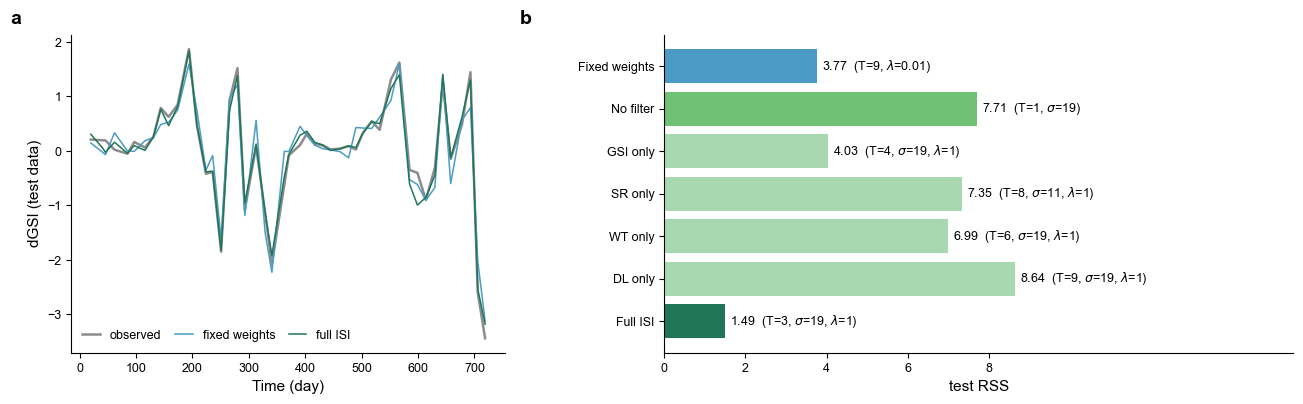

In [19]:
def bar_color(model_name):
    return STRUCTURAL_COLORS.get(model_name, INPUT_RESTRICTED_COLOR)


def format_hyperparameters(row):
    """(T, sigma, lambda), omitting what does not apply to the model."""
    parts = [f"T={int(row['kernel size'])}"]
    if np.isfinite(row["process noise"]):
        parts.append(r"$\sigma$=" + f"{row['process noise']:g}")
    if int(row["kernel size"]) > 1:
        parts.append(r"$\lambda$=" + f"{row['ridge penalty']:.2g}")
    return ", ".join(parts)


figure = plt.figure(figsize=(13.0, 4.3))
grid = figure.add_gridspec(1, 2, width_ratios=[1.0, 1.45], wspace=0.30,
                           left=0.055, right=0.995, top=0.93, bottom=0.19)

# (a) the test group under the reported model and under the fixed-weight model
axis_trace = figure.add_subplot(grid[0, 0])
axis_trace.plot(ladder_times, observed, color="black", alpha=0.45,
                linewidth=1.8, label="observed")
axis_trace.plot(ladder_times, prediction_fixed, color=RESPONSE_FUNCTION_ONLY_COLOR,
                linewidth=1.1, label="fixed weights")
axis_trace.plot(ladder_times, prediction_full, color=REPORTED_MODEL_COLOR,
                linewidth=1.1, label="full ISI")
axis_trace.set_xlabel("Time (day)", fontsize=11)
axis_trace.set_ylabel("dGSI (test data)", fontsize=11)
axis_trace.legend(frameon=False, fontsize=9, ncol=3, loc="lower left",
                  columnspacing=1.1, handlelength=1.4)
axis_trace.spines[["top", "right"]].set_visible(False)
axis_trace.tick_params(labelsize=9)

# (b) every model at its own selected hyperparameters
axis_ladder = figure.add_subplot(grid[0, 1])
ordered = performance.loc[[label for label, *_ in MODEL_LADDER]]
bars = axis_ladder.barh(range(len(ordered)), ordered["test RSS"],
                        color=[bar_color(name) for name in ordered.index])
for bar, (_, row) in zip(bars, ordered.iterrows()):
    axis_ladder.text(row["test RSS"] + 0.12, bar.get_y() + bar.get_height() / 2,
                     f"{row['test RSS']:.2f}  ({format_hyperparameters(row)})",
                     va="center", fontsize=9)
axis_ladder.set_yticks(range(len(ordered)))
axis_ladder.set_yticklabels(ordered.index, fontsize=10)
axis_ladder.invert_yaxis()
axis_ladder.set_xlim(0, 15.5)
axis_ladder.set_xticks([0, 2, 4, 6, 8])
axis_ladder.set_xlabel("test RSS", fontsize=11)
axis_ladder.spines[["top", "right"]].set_visible(False)
axis_ladder.tick_params(labelsize=9)

for label, x in [("a", 0.008), ("b", 0.400)]:
    figure.text(x, 0.955, label, fontsize=14, fontweight="bold")

#figure.savefig(OUTPUT_DIRECTORY / "SupplementaryFigureR4.pdf", bbox_inches="tight")
#figure.savefig(OUTPUT_DIRECTORY / "SupplementaryFigureR4.png", dpi=200, bbox_inches="tight")
plt.show()

# Part II — ablation of the time-varying weights 

## 9. The constrained estimator

One signal at a time, $w_i$ is held constant in time and the model is refitted. Holding $w_i$
at one loses no generality, because multiplying $w_i$ by a constant and dividing $f_i$ by the
same constant leaves the prediction unchanged, so the ridge step recovers the constant as
part of $f_i$.

The constraint is imposed inside the filter, by removing the process noise and the initial
uncertainty of that component, so that the Kalman gain of its row vanishes and every
innovation is attributed to the components that are still free. Projecting the smoothed state
onto one afterwards would instead discard corrections that the filter had already assigned to
the constrained component, which degrades the remaining estimates and gives a misleading
answer.

In [20]:
FROZEN_VARIANCE = 1e-9   # a state with no process noise and no initial uncertainty


class EMAlgorithmWithConstantWeights(EMAlgorithmCompatible):
    """The ISI model with the weights of selected signals held constant in time."""

    def __init__(self, *args, constant_signals=(), **kwargs):
        super().__init__(*args, **kwargs)
        self.constant_signals = tuple(constant_signals)

    def _kalman_smooth(self, H, Y, x0, P0, dt):
        x0, P0 = np.asarray(x0, float).copy(), np.asarray(P0, float).copy()
        for signal_index in self.constant_signals:
            self.W[signal_index, :] = 0.0
            self.W[:, signal_index] = 0.0
            self.W[signal_index, signal_index] = FROZEN_VARIANCE
            P0[signal_index, :] = 0.0
            P0[:, signal_index] = 0.0
            P0[signal_index, signal_index] = FROZEN_VARIANCE
            x0[signal_index] = 1.0
        x_filt, P_filt, x_smooth, P_smooth = super()._kalman_smooth(H, Y, x0, P0, dt)
        for signal_index in self.constant_signals:
            x_filt[:, signal_index] = 1.0
            x_smooth[:, signal_index] = 1.0
        return x_filt, P_filt, x_smooth, P_smooth

## 10. Data at the reported hyperparameters

The ablation is run at the hyperparameters of the main analysis, so that the constrained
models differ from the reported model in one respect only. The evaluation set starts at the
first day with $T$ lags available, which leaves 48 sampling days. Part I aligns all kernel
sizes on a common lag axis and uses 47, so the residual sums of squares of the two parts are
on slightly different evaluation sets.

In [21]:
KERNEL_SIZE = 3
PROCESS_NOISE = 19
RIDGE_PENALTY = 1.0
N_SIGNALS = len(SIGNAL_NAMES)

ablation_inputs, ablation_outputs, ablation_times = build_sliding_window(
    input_df, output_df, KERNEL_SIZE, first_valid_day=KERNEL_SIZE)
print(f"sampling days: {len(ablation_times)} "
      f"({ablation_times[0]:g} to {ablation_times[-1]:g})")

sampling days: 48 (5 to 719)


## 11. Cross-validated score and agreement of the retained weights

Two quantities are computed for every model.

`test RSS` is the mean residual sum of squares under the same three-fold cross-validation as
Part I. `corr w` is the Pearson correlation between each retained weight and its counterpart
in the unconstrained model, both fitted to all three groups and both normalized to unit
temporal RMS, which removes the scale that $w_i$ and $f_i$ can trade between them.

The same fit to all three groups also gives the waveforms of panels (c) to (g).

In [23]:
def cross_validated_score(constant_signals=()):
    """Mean test residual sum of squares over the three group splits."""
    residual_sums = []
    for train_a, train_b, test in GROUP_SPLITS:
        model = EMAlgorithmWithConstantWeights(
            window_size=KERNEL_SIZE, process_noise_var=PROCESS_NOISE,
            alpha=RIDGE_PENALTY, constant_signals=constant_signals)
        importance, _, filters, _, _ = model.fit(
            X_list=[ablation_inputs[train_a], ablation_inputs[train_b]],
            Y_list=[ablation_outputs[:, train_a], ablation_outputs[:, train_b]],
            times=ablation_times, n_signals=N_SIGNALS)
        _, prediction = model.test(X_list=[ablation_inputs[test]],
                                   Y_list=[ablation_outputs[:, test]],
                                   x_smooth=importance, coef=filters)
        residual_sums.append(
            float(np.sum((ablation_outputs[:, test] - prediction[0]) ** 2)))
    return float(np.mean(residual_sums))


def fit_all_groups(constant_signals=()):
    """Signal importance in the scale RMS_t[w_i] = 1, and the prediction for group 0."""
    model = EMAlgorithmWithConstantWeights(
        window_size=KERNEL_SIZE, process_noise_var=PROCESS_NOISE,
        alpha=RIDGE_PENALTY, constant_signals=constant_signals)
    importance, _, filters, _, _ = model.fit(
        X_list=list(ablation_inputs),
        Y_list=[ablation_outputs[:, g] for g in range(3)],
        times=ablation_times, n_signals=N_SIGNALS)

    importance = np.asarray(importance, float).copy()
    filters = np.asarray(filters, float).reshape(N_SIGNALS, KERNEL_SIZE).copy()
    for i in range(N_SIGNALS):
        typical = np.sqrt(np.mean(importance[:, i] ** 2))
        filters[i] *= typical
        importance[:, i] /= typical

    processed = np.column_stack([
        ablation_inputs[0][:, i * KERNEL_SIZE:(i + 1) * KERNEL_SIZE] @ filters[i]
        for i in range(N_SIGNALS)])
    return importance, (importance * processed).sum(axis=1)


scores = {"none (full ISI)": cross_validated_score()}
importances, predictions = {}, {}
importances["full"], predictions["full"] = fit_all_groups()
print(f"full ISI: test RSS = {scores['none (full ISI)']:.4f}", flush=True)

correlations = {}
for signal_index, name in enumerate(SIGNAL_NAMES):
    scores[name] = cross_validated_score((signal_index,))
    importances[name], predictions[name] = fit_all_groups((signal_index,))
    correlations[name] = {
        other: float(np.corrcoef(importances["full"][:, other_index],
                                 importances[name][:, other_index])[0, 1])
        for other_index, other in enumerate(SIGNAL_NAMES) if other_index != signal_index}
    print(f"w_{name} constant: test RSS = {scores[name]:.4f}, "
          + ", ".join(f"corr w_{k} = {v:.3f}"
                      for k, v in correlations[name].items()), flush=True)

scores = pd.Series(scores, name="test RSS")
correlations = pd.DataFrame(correlations).T.reindex(index=SIGNAL_NAMES, columns=SIGNAL_NAMES)

rss: 0.649233546532213
rss: 0.3969918590993885
rss: 0.5941241835357507
rss: 0.6044465532353267
full ISI: test RSS = 1.5670
rss: 0.7152581989156634
rss: 0.35670647180945436
rss: 0.6739078381343666
rss: 0.6729655073036117
w_SR constant: test RSS = 1.7498, corr w_WT = 0.565, corr w_DL = 0.536, corr w_GSI = 0.826
rss: 0.7305971066191688
rss: 0.3715547736903559
rss: 0.5738273086474383
rss: 0.6337681834324896
w_WT constant: test RSS = 1.4891, corr w_SR = 0.624, corr w_DL = 0.968, corr w_GSI = 0.918
rss: 0.6128166705454635
rss: 0.30603590255935686
rss: 0.5998325861941172
rss: 0.5896736928060556
w_DL constant: test RSS = 1.6343, corr w_SR = 0.972, corr w_WT = 0.964, corr w_GSI = 0.990
rss: 3.639040254372822
rss: 1.7546038840268916
rss: 1.6926636753246322
rss: 3.1794922592779025
w_GSI constant: test RSS = 6.9847, corr w_SR = 0.626, corr w_WT = 0.494, corr w_DL = -0.744


In [24]:
print(correlations.round(3).to_string())
print()
print("mean correlation of the retained weights with the full model")
print(correlations.mean(axis=1).round(3).to_string())

        SR     WT     DL    GSI
SR     NaN  0.565  0.536  0.826
WT   0.624    NaN  0.968  0.918
DL   0.972  0.964    NaN  0.990
GSI  0.626  0.494 -0.744    NaN

mean correlation of the retained weights with the full model
SR     0.642
WT     0.836
DL     0.975
GSI    0.125


## 12. Figure S11

The bars of the constrained models in panel (a) are drawn unfilled and hatched in the colour
of the ablated channel, which marks that this channel no longer carries a time-varying
weight. The bars of panel (b) are the weights that remain, so they are drawn filled.

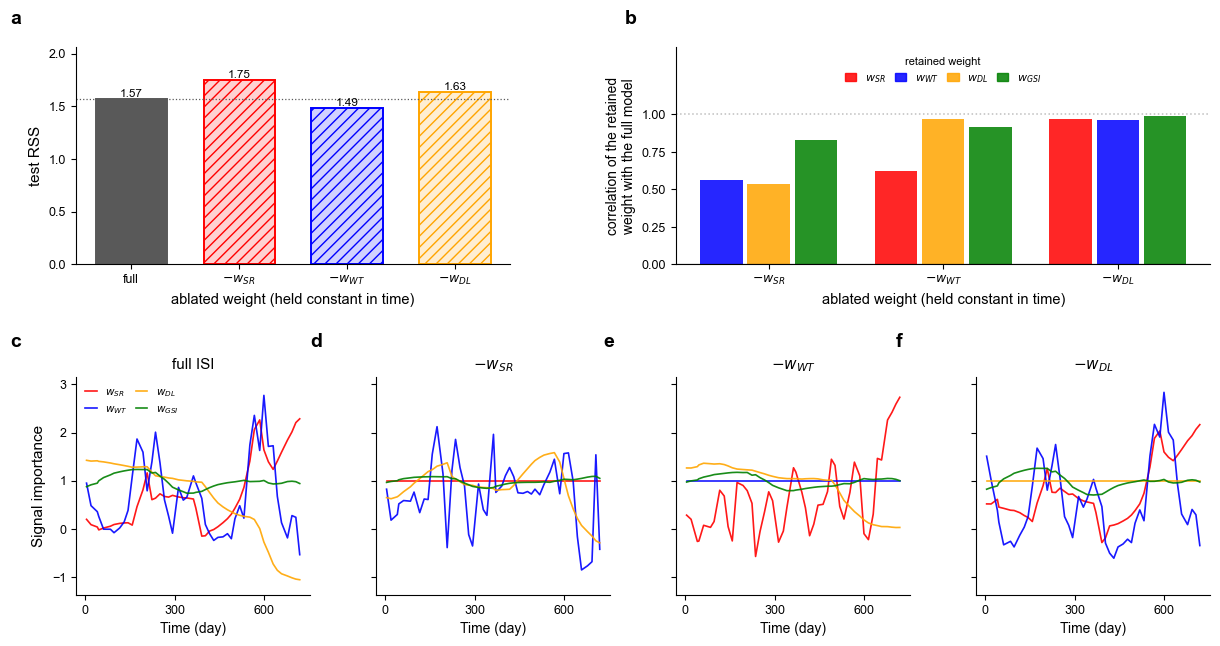

In [27]:
SIGNAL_COLORS = ["red", "blue", "orange", "green"]
COLOR_OF = dict(zip(SIGNAL_NAMES, SIGNAL_COLORS))
FULL_MODEL_COLOR = "0.35"
ABLATED_SIGNALS = [name for name in SIGNAL_NAMES if name != "GSI"]  # GSI ablation は非表示

figure = plt.figure(figsize=(12.2, 6.6))
grid = figure.add_gridspec(2, 12, hspace=0.52, wspace=1.9,
                           left=0.06, right=0.99, top=0.93, bottom=0.10)

# (a) predictive accuracy barely distinguishes the environmental signals
axis_score = figure.add_subplot(grid[0, 0:5])
labels = ["full"] + [f"$-w_{{{name}}}$" for name in ABLATED_SIGNALS]
values = [scores["none (full ISI)"]] + [scores[name] for name in ABLATED_SIGNALS]
bar_colors = [FULL_MODEL_COLOR] + [COLOR_OF[name] for name in ABLATED_SIGNALS]
bars = axis_score.bar(labels, values, width=0.66, color="white",
                      edgecolor=bar_colors, linewidth=1.4)
for position, (bar, value, color) in enumerate(zip(bars, values, bar_colors)):
    if position == 0:
        bar.set_facecolor(color)
    else:
        # the ablated signal is the one that is absent, so its bar is left unfilled
        bar.set_facecolor(matplotlib.colors.to_rgba(color, 0.18))
        bar.set_hatch("///")
    axis_score.text(bar.get_x() + bar.get_width() / 2, value + 0.02, f"{value:.2f}",
                    ha="center", fontsize=8.5)
axis_score.axhline(scores["none (full ISI)"], color=FULL_MODEL_COLOR, linewidth=0.9,
                   linestyle=":")
axis_score.set_ylim(0, max(values) * 1.18)
axis_score.set_ylabel("test RSS", fontsize=11)
axis_score.set_xlabel("ablated weight (held constant in time)", fontsize=10.5)
axis_score.spines[["top", "right"]].set_visible(False)
axis_score.tick_params(labelsize=9)

# (b) the weights that remain do not keep their shape
axis_correlation = figure.add_subplot(grid[0, 6:12])
width = 0.27
for ablated_index, ablated in enumerate(ABLATED_SIGNALS):
    for offset, name in zip([-1, 0, 1], [n for n in SIGNAL_NAMES if n != ablated]):
        axis_correlation.bar(ablated_index + offset * width,
                             correlations.loc[ablated, name], width=width * 0.9,
                             color=COLOR_OF[name], alpha=0.85)
axis_correlation.axhline(1.0, color="0.75", linestyle=":", linewidth=1.1)
axis_correlation.axhline(0.0, color="black", linewidth=0.8)
axis_correlation.legend([plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.85)
                         for c in SIGNAL_COLORS],
                        [f"$w_{{{name}}}$" for name in SIGNAL_NAMES],
                        frameon=False, fontsize=8, ncol=4, loc="upper center",
                        columnspacing=0.8, handlelength=1.0,
                        title="retained weight", title_fontsize=8)
axis_correlation.set_xticks(np.arange(len(ABLATED_SIGNALS)))
axis_correlation.set_xticklabels([f"$-w_{{{name}}}$" for name in ABLATED_SIGNALS],
                                 fontsize=10)
axis_correlation.set_ylim(0, 1.45)
axis_correlation.set_yticks([0, 0.25, 0.5, 0.75, 1])
axis_correlation.set_ylabel("correlation of the retained\nweight with the full model",
                            fontsize=10)
axis_correlation.set_xlabel("ablated weight (held constant in time)", fontsize=10.5)
axis_correlation.spines[["top", "right"]].set_visible(False)
axis_correlation.tick_params(labelsize=9)

# (c-f) the signal importance of every model, one panel per ablation
model_panels = [("full", "full ISI")] + \
               [(name, f"$-w_{{{name}}}$") for name in ABLATED_SIGNALS]
lower = min(importances[key].min() for key, _ in model_panels)
upper = max(importances[key].max() for key, _ in model_panels)
margin = 0.08 * (upper - lower)
for panel_index, (key, title) in enumerate(model_panels):
    axis = figure.add_subplot(grid[1, 3 * panel_index:3 * panel_index + 3])
    for signal_index, signal in enumerate(SIGNAL_NAMES):
        axis.plot(ablation_times, importances[key][:, signal_index],
                  color=COLOR_OF[signal], linewidth=1.2, alpha=0.9,
                  label=f"$w_{{{signal}}}$")
    axis.set_title(title, fontsize=11)
    axis.set_ylim(lower - margin, upper + margin)
    axis.set_xticks([0, 300, 600])
    axis.set_xlabel("Time (day)", fontsize=10)
    if panel_index == 0:
        axis.set_ylabel("Signal importance", fontsize=11)
        axis.legend(frameon=False, fontsize=7.5, ncol=2, loc="upper left",
                    columnspacing=0.8, handlelength=1.1)
    else:
        axis.set_yticklabels([])
    axis.spines[["top", "right"]].set_visible(False)
    axis.tick_params(labelsize=9)

for label, x, y in [("a", 0.006, 0.965), ("b", 0.510, 0.965),
                    ("c", 0.006, 0.475), ("d", 0.252, 0.475),
                    ("e", 0.492, 0.475), ("f", 0.732, 0.475)]:
    figure.text(x, y, label, fontsize=14, fontweight="bold")

plt.show()

# Part III — robustness to the ridge penalty

The solution reported in the manuscript uses the ridge penalty $\lambda = 1$. Here the
same analysis is repeated at $\lambda \in \{0.1, 0.3, 0.5, 1, 2, 3, 10\}$ and the
agreement of each solution with the reported one is quantified for the signal
importance and for the response functions, both by Pearson correlation; the
amplitude of a response function is a gauge choice, so only its shape enters the
comparison.


## 13. Gauge fixing, agreement metrics and the figure

In [12]:
"""Robustness of the ISI inference to the ridge penalty lambda.

The full grid search (kernel size and process noise) is repeated for each penalty, so the
selected kernel size may differ between penalties.

* Signal importance is indexed by sampling time and is therefore comparable across
  penalties regardless of the kernel size that was selected.
* Response functions are compared after zero-padding the shorter kernel. The kernel-size
  grid is nested, so a kernel of length W is exactly a longer kernel whose additional
  far-lag taps are constrained to zero; filters are aligned at lag 0 (the last tap).
  The padded taps are genuine model values, so the padded kernels are both compared and
  plotted over the common window.
* Every solution is expressed in the canonical gauge RMS_t[w_i] = 1 before plotting. This
  is an exact per-signal reparameterization, so it changes neither the model fit nor the
  reported metrics; it only removes amplitude differences that are pure gauge.
* Response functions are compared by Pearson correlation, since their amplitude is a
  gauge choice; they are drawn normalized to unit norm for the same reason, and their
  canonical-gauge amplitude is reported separately in the table. Signal importance is
  likewise compared by Pearson correlation, which is invariant to the gauge.

Expects, in ./supresults_BestModelsForEachLamda/:
    SignalImportance_average_alpha{tag}.csv   index, Time, Time_raw, SR, WT, DL, GSI
    ResponseFunction_average_alpha{tag}.csv   n_signals rows x window_size columns
with tag = f"{penalty:g}".replace(".", "")   e.g. 0.1 -> "01", 1.0 -> "1", 10.0 -> "10".
"""

from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SIGNAL_NAMES = ["SR", "WT", "DL", "GSI"]
SIGNAL_LABELS = [r"$\mathbf{w}_{SR}$", r"$\mathbf{w}_{WT}$",
                 r"$\mathbf{w}_{DL}$", r"$\mathbf{w}_{GSI}$"]
FILTER_LABELS = [r"$\mathbf{f}_{SR}$", r"$\mathbf{f}_{WT}$",
                 r"$\mathbf{f}_{DL}$", r"$\mathbf{f}_{GSI}$"]
N_SIGNALS = len(SIGNAL_NAMES)

RESULT_DIRECTORY = Path("./RevisedFigure")
CONSTANT_IMPORTANCE_SD = 0.05      # below this, w_i is flat and its correlation is void
RIDGE_PENALTIES = [0.1, 0.3, 0.5, 1.0, 2.0, 3.0,  10.0]
REPORTED_PENALTY = 1.0

matplotlib.rcParams["pdf.fonttype"] = 42
if "Arial" in {font.name for font in matplotlib.font_manager.fontManager.ttflist}:
    matplotlib.rcParams["font.family"] = "Arial"


# --------------------------------------------------------------------------- loading


def penalty_tag(penalty):
    """Filename token for a penalty: 0.1 -> '01', 1.0 -> '1', 10.0 -> '10'."""

    return f"{penalty:g}".replace(".", "")



def pad_response_functions(filters, target_window_size):
    """Embed a shorter kernel in a longer window by zero-filling the far-lag taps."""
    padded = np.zeros((filters.shape[0], target_window_size))
    padded[:, target_window_size - filters.shape[1]:] = filters
    return padded


# --------------------------------------------------------------------------- gauge & metrics

def apply_gauge_fixing(filters, importance):
    """Canonical gauge RMS_t[w_i] = 1; the amplitude moves into f_i."""
    gauge_fixed_filters, gauge_fixed_importance = filters.copy(), importance.copy()
    for i in range(N_SIGNALS):
        typical_importance = np.sqrt(np.mean(gauge_fixed_importance[:, i] ** 2))
        gauge_fixed_filters[i] *= typical_importance
        gauge_fixed_importance[:, i] /= typical_importance
    return gauge_fixed_filters, gauge_fixed_importance


def filter_correlation(first_filter, second_filter):
    return float(np.corrcoef(first_filter, second_filter)[0, 1])


def summarize_agreement(solutions, kernel_sizes, reference=REPORTED_PENALTY):
    """Agreement of each solution with the reported one."""
    reference_filters, reference_importance = solutions[reference]
    records = []
    for penalty, (filters, importance) in solutions.items():
        record = {"ridge penalty": penalty, "kernel size": kernel_sizes[penalty]}
        for i, name in enumerate(SIGNAL_NAMES):
            record[f"corr w {name}"] = float(np.corrcoef(
                reference_importance[:, i], importance[:, i])[0, 1])
        for i, name in enumerate(SIGNAL_NAMES):
            record[f"corr f {name}"] = filter_correlation(reference_filters[i], filters[i])
        # a correlation is uninformative for a trajectory that is essentially constant
        for i, name in enumerate(SIGNAL_NAMES):
            record[f"sd w {name}"] = float(importance[:, i].std())
        for i, name in enumerate(SIGNAL_NAMES):
            record[f"|f| {name}"] = float(np.linalg.norm(filters[i]))
        records.append(record)
    return pd.DataFrame(records).set_index("ridge penalty")


# --------------------------------------------------------------------------- figure

def plot_robustness(solutions, kernel_sizes, sampling_times, common_window, agreement,
                    penalties=RIDGE_PENALTIES, output_stem="RidgePenaltyRobustness"):
    penalty_colors = {p: color for p, color in
                      zip(penalties, plt.cm.viridis(np.linspace(0, 0.88, len(penalties))))}

    figure = plt.figure(figsize=(13.5, 10.2))
    grid = figure.add_gridspec(3, 4, hspace=0.55, wspace=0.35,
                               left=0.07, right=0.985, top=0.93, bottom=0.07)

    # (a) response functions, one panel per signal
    for i, label in enumerate(FILTER_LABELS):
        axis = figure.add_subplot(grid[0, i])
        for penalty in penalties:
            # the zero-padded kernel is plotted over the full common window; only its
            # direction is meaningful, so it is drawn normalized to unit norm
            filter_direction = (solutions[penalty][0][i]
                                / np.linalg.norm(solutions[penalty][0][i]))
            axis.plot(range(common_window), filter_direction, "o-",
                      color=penalty_colors[penalty],
                      linewidth=1.6 if penalty == REPORTED_PENALTY else 1.1,
                      markersize=4,
                      label=f"$\\lambda$ = {penalty:g}"
                            + (" (W = %d)" % kernel_sizes[penalty]
                               if kernel_sizes[penalty] != common_window else ""))
        axis.set_title(label, fontsize=12)
        axis.set_xticks(range(common_window))
        axis.set_xticklabels(range(common_window - 1, -1, -1), fontsize=10)
        axis.set_xlabel("Lag (days)", fontsize=10)
        axis.tick_params(axis="y", labelsize=9)
        axis.spines[["top", "right"]].set_visible(False)
        if i == 0:
            axis.set_ylabel("Response function", fontsize=11)
        if i == N_SIGNALS - 1:
            axis.legend(frameon=False, fontsize=8, loc="upper left")

    # (b) signal importance, one panel per signal
    for i, label in enumerate(SIGNAL_LABELS):
        axis = figure.add_subplot(grid[1, i])
        for penalty in penalties:
            axis.plot(sampling_times, solutions[penalty][1][:, i],
                      color=penalty_colors[penalty],
                      linewidth=1.8 if penalty == REPORTED_PENALTY else 1.1)
        axis.set_title(label, fontsize=12)
        axis.set_xticks([0, 200, 400, 600])
        axis.set_xlabel("Time (day)", fontsize=10)
        axis.tick_params(labelsize=9)
        axis.spines[["top", "right"]].set_visible(False)
        if i == 0:
            axis.set_ylabel("Signal importance", fontsize=11)

    # (c, d) agreement with the reported solution
    axis_importance = figure.add_subplot(grid[2, 0:2])
    axis_filters = figure.add_subplot(grid[2, 2:4])
    signal_colors = ["red", "blue", "orange", "green"]
    for i, (name, color) in enumerate(zip(SIGNAL_NAMES, signal_colors)):
        # a flat trajectory carries no shape, so its correlation is not interpretable
        is_constant = agreement[f"sd w {name}"] < CONSTANT_IMPORTANCE_SD
        for axis, column in [(axis_importance, f"corr w {name}"),
                             (axis_filters, f"corr f {name}")]:
            axis.plot(penalties, agreement[column], "-",
                      color=color, linewidth=1.4, label=name)
            axis.plot(agreement.index[~is_constant], agreement.loc[~is_constant, column],
                      "o", color=color, markersize=5)
            axis.plot(agreement.index[is_constant], agreement.loc[is_constant, column],
                      "o", markerfacecolor="white", markeredgecolor=color, markersize=5)

    for axis, ylabel, title in [
            (axis_importance, r"correlation with $\lambda = 1$", "Signal importance"),
            (axis_filters, r"correlation with $\lambda = 1$", "Response function")]:
      
        axis.set_xscale("log")
        axis.set_xticks(penalties)
        axis.set_xticklabels([f"{p:g}" for p in penalties], fontsize=10)
        axis.set_xlabel(r"Ridge penalty $\lambda$", fontsize=11)
        axis.set_ylabel(ylabel, fontsize=11)
        axis.set_title(title, fontsize=12)
        axis.tick_params(labelsize=9)
        axis.spines[["top", "right"]].set_visible(False)
        axis.legend(frameon=False, fontsize=9, ncol=2)


    for label, x, y in [("a", 0.012, 0.965), ("b", 0.012, 0.645), ("c", 0.012, 0.325),
                        ("d", 0.512, 0.325)]:
        figure.text(x, y, label, fontsize=15, fontweight="bold")

    figure.savefig(RESULT_DIRECTORY / f"{output_stem}.pdf", bbox_inches="tight")
    #figure.savefig(RESULT_DIRECTORY / f"{output_stem}.png", dpi=200, bbox_inches="tight")
    plt.show()


## 14. The per-λ solutions, the agreement table and the figure

Input files, one pair per penalty, in `supresults_BestModelsForEachLamda/`:

* `SignalImportance_average_alpha{tag}.csv` — averaged signal importance for each λ
* `ResponseFunction_average_alpha{tag}.csv` — averaged response function for each λ

At each **λ**, the solution was derived by the same procedure as in the main analysis:

1. A **grid search** over the remaining hyperparameters — **T** (kernel size) and
   **σ** (process noise of the Kalman filter).
2. The **average of the estimated solutions** with comparable performance, where
   performance is measured by **RSS** rounded to one decimal place.
3. Within the comparable set, a **kernel size of 3** was selected preferentially.


               kernel size  corr w SR  corr w WT  corr w DL  corr w GSI  corr f SR  corr f WT  corr f DL  corr f GSI  sd w SR  sd w WT  sd w DL  sd w GSI  |f| SR  |f| WT  |f| DL  |f| GSI
ridge penalty                                                                                                                                                                             
0.1                      3      0.787      0.822      0.267       0.871      1.000      0.507      0.998       1.000    0.743    0.581    0.658     0.164   0.321   0.474   0.215   11.156
0.3                      3      0.850      0.865      0.436       0.961      1.000      0.827     -0.943       1.000    0.799    0.616    0.595     0.140   0.332   0.345   0.165   11.459
0.5                      3      0.924      0.911      0.771       0.985      1.000      0.949     -0.975       1.000    0.776    0.641    0.600     0.130   0.363   0.321   0.124   11.663
1.0                      3      1.000      1.000      1.000      

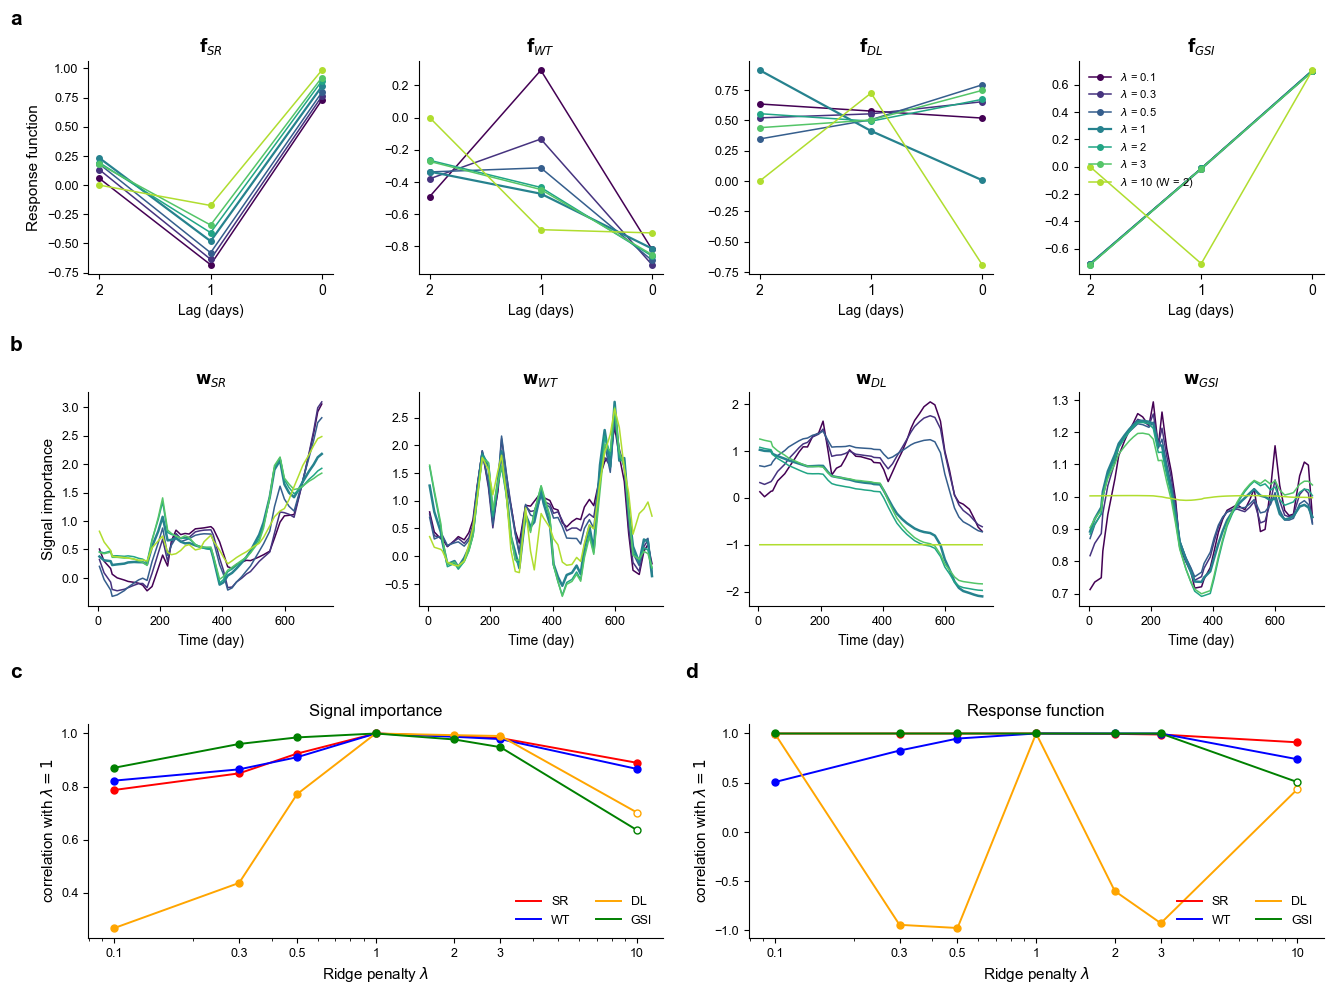

In [13]:
def load_signal_importance(penalty):
    table = pd.read_csv(f"./BestModelsForEachLamda/SignalImportance_average_alpha{penalty_tag(penalty)}.csv",
        index_col=0)
    return table[SIGNAL_NAMES].to_numpy(dtype=float), table["Time"].to_numpy(dtype=float)


def load_response_functions(penalty):
    """(n_signals, window_size); the last column is the sampling day (lag 0)."""
    return np.atleast_2d(np.loadtxt(f"./BestModelsForEachLamda/ResponseFunction_average_alpha{penalty_tag(penalty)}.csv"))

def load_all_solutions(penalties=RIDGE_PENALTIES):
    """Every solution in the canonical gauge, on a common kernel length."""
    raw_filters = {p: load_response_functions(p) for p in penalties}
    common_window = max(f.shape[1] for f in raw_filters.values())

    solutions, kernel_sizes = {}, {}
    for penalty in penalties:
        importance, sampling_times = load_signal_importance(penalty)
        filters = pad_response_functions(raw_filters[penalty], common_window)
        solutions[penalty] = apply_gauge_fixing(filters, importance)
        kernel_sizes[penalty] = raw_filters[penalty].shape[1]
    return solutions, kernel_sizes, sampling_times, common_window


solutions, kernel_sizes, sampling_times, common_window = load_all_solutions()
agreement = summarize_agreement(solutions, kernel_sizes)

pd.set_option("display.width", 260)
print(agreement.round(3).to_string())
#agreement.round(4).to_csv(RESULT_DIRECTORY / "RidgePenaltyRobustness.csv")


   
plot_robustness(solutions, kernel_sizes, sampling_times, common_window, agreement)